# MOSS Digital Twin
**Multi-beam Optical Stress Sensor — system constants and calculation chain**

Signal chain: film stress → substrate curvature → surface slope → beam deflection → beam spacing change on CCD → curvature → film stress

All quantities in SI. Convert only for display.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace

## 1  Optical system constants
Source: `literature/Multi-beam-optical-layout.png` and §5 of `Thin_Film_Stress_Measurement_System.pdf`

In [4]:
optics = SimpleNamespace(
    # Laser
    lambda_laser   = 650e-9,   # m   — diode, 635–670 nm; 650 nm nominal

    # MOSS etalon  (α_e = 50° incidence on a 5 mm glass plate → d₀ = 4 mm)
    alpha_e_deg    = 50.0,     # deg — angle of incidence on etalon, measured from surface normal
    t_etalon       = 5e-3,     # m   — etalon plate thickness
    d0             = 4e-3,     # m   — initial beam spacing leaving the etalon
    n_beams        = 3,        # —   — aperture blocks 4th and higher reflections

    # Sample geometry
    alpha_sample_deg = 10.0,   # deg — oblique incidence angle on sample (from surface normal)
                               #       beams leave etalon 10° from vertical

    # Optical lever arm
    # L is the beam path from sample to detector: physical distance / cos(10°) ≈ 0.152 m
    L              = 0.152,    # m   — lever arm (beam path, angle-corrected)

    # Detector
    # Camera tilted 10° to face reflected beams so the spot pattern is not stretched
    detector_tilt_deg = 10.0,  # deg — camera tilt matching beam incidence
)

print(f"Etalon incidence : {optics.alpha_e_deg}°")
print(f"Initial spacing  : d₀ = {optics.d0*1e3:.1f} mm")
print(f"Lever arm        : L  = {optics.L*1e2:.1f} cm")
print(f"Sample incidence : α  = {optics.alpha_sample_deg}°")

Etalon incidence : 50.0°
Initial spacing  : d₀ = 4.0 mm
Lever arm        : L  = 15.2 cm
Sample incidence : α  = 10.0°


## 2  Substrate and film defaults
Source: Table 1 of `Thin_Film_Stress_Measurement_System.pdf` — Si(100) representative example

In [5]:
substrate = SimpleNamespace(
    material   = "Si(100)",
    t_s        = 300e-6,       # m   — substrate thickness; range 100–300 µm (source: Patric)
    E_s        = 169e9,        # Pa  — Young's modulus, Si(100) in-plane
    nu_s       = 0.064,        # —   — Poisson's ratio, Si(100)
    alpha_s    = 2.6e-6,       # 1/K — CTE of silicon
)
# Biaxial modulus G_s = E_s / (1 − ν_s)  — Stoney's equation uses this
substrate.G_s = substrate.E_s / (1 - substrate.nu_s)  # Pa  (confirmed ≈ 180 GPa, source: Patric Gruber, email 12 Nov 2026)

film = SimpleNamespace(
    # Paint film — values from Patric (email, 12 Nov 2026)
    t_f  = 20e-6,              # m   — nominal film thickness; range 10–30 µm
    G_f  = 2e9,                # Pa  — biaxial modulus; range 1–3 GPa
)

print(f"Substrate : {substrate.material}, t_s = {substrate.t_s*1e6:.0f} µm  (range 100–300 µm)")
print(f"G_s       = {substrate.G_s/1e9:.1f} GPa  (confirmed ≈ 180 GPa)")
print(f"Film      : t_f = {film.t_f*1e6:.0f} µm  (range 10–30 µm),  G_f = {film.G_f/1e9:.0f} GPa  (range 1–3 GPa)")

Substrate : Si(100), t_s = 300 µm  (range 100–300 µm)
G_s       = 180.6 GPa  (confirmed ≈ 180 GPa)
Film      : t_f = 20 µm  (range 10–30 µm),  G_f = 2 GPa  (range 1–3 GPa)


## 3  Copper stage constants
Source: `Copper_stage_design_report.pdf` — Cu OFE C10100 at 20 °C

In [6]:
stage = SimpleNamespace(
    material    = "Cu OFE C10100",

    # Thermal-physical properties (KME sheet, 20 °C)
    rho         = 8930.0,      # kg/m³  — density
    cp          = 390.0,       # J/(kg·K) — specific heat
    k_thermal   = 394.0,       # W/(m·K)  — thermal conductivity
    alpha_CTE   = 17.7e-6,     # 1/K      — mean CTE over 20–300 °C range
    E           = 130e9,       # Pa       — elastic modulus

    # Stage body geometry (40 × 20 mm footprint; thickness TBD from thermal model)
    stage_L     = 40e-3,       # m   — stage length
    stage_W     = 20e-3,       # m   — stage width
    stage_T     = None,        # m   — thickness: to be determined from heat-balance simulation

    # Sample footprint
    sample_L    = 30e-3,       # m   — sample length
    sample_W    = 10e-3,       # m   — sample width

    # Three-point support contact coordinates [x, y] in metres, origin at sample centre
    # Layout A — equal end distances
    support_A   = np.array([[-10, -3], [-10, +3], [+10,  0]]) * 1e-3,
    # Layout B — equal nominal reaction loads
    support_B   = np.array([[ -6, -3], [ -6, +3], [+12,  0]]) * 1e-3,
)

print(f"Stage material : {stage.material}")
print(f"Conductivity   : {stage.k_thermal} W/(m·K)")
print(f"Support A      : {stage.support_A * 1e3} mm")
print(f"Support B      : {stage.support_B * 1e3} mm")

Stage material : Cu OFE C10100
Conductivity   : 394.0 W/(m·K)
Support A      : [[-10.  -3.]
 [-10.   3.]
 [ 10.   0.]] mm
Support B      : [[-6. -3.]
 [-6.  3.]
 [12.  0.]] mm


## 4  Temperature range

In [7]:
thermal = SimpleNamespace(
    T_min          = 223.15,   # K  — lower limit  (−50 °C)
    T_max          = 373.15,   # K  — upper limit  (+100 °C)
    T_ref          = 293.15,   # K  — reference    (+20 °C)
    ramp_rate_min  = 1/60,     # K/s — lower ramp rate (1 K/min)
    ramp_rate_max  = 2/60,     # K/s — upper ramp rate (2 K/min)
    delta_sigma_target = 1e6,  # Pa  — stress resolution goal (≲1 MPa, to be confirmed)
)

print(f"T range  : {thermal.T_min - 273.15:.0f} °C to {thermal.T_max - 273.15:.0f} °C")
print(f"Ramp     : {thermal.ramp_rate_min*60:.0f}–{thermal.ramp_rate_max*60:.0f} K/min")
print(f"Δσ goal  : ≲{thermal.delta_sigma_target/1e6:.0f} MPa")

T range  : -50 °C to 100 °C
Ramp     : 1–2 K/min
Δσ goal  : ≲1 MPa


## 5  Optical functions: beam spacing ↔ curvature

MOSS equation (§3.3, Eq. 6):

$$d = d_0 (1 + 2\kappa L / \cos\alpha) \quad\Leftrightarrow\quad \kappa = \frac{\cos\alpha}{2L}\left(\frac{d}{d_0} - 1\right)$$

Tilt and vibration move all beams equally and cancel in the spacing ratio $d/d_0$.

In [10]:
def curvature_from_spacing(d, d0, L, alpha_deg):
    """Curvature κ [1/m] from measured beam spacing d [m].

    Parameters
    ----------
    d         : measured beam spacing on CCD [m], scalar or array
    d0        : reference spacing on flat sample [m]
    L         : optical lever arm (beam path sample→detector) [m]
    alpha_deg : angle of incidence on sample [degrees]
    """
    cos_a = np.cos(np.radians(alpha_deg))
    return (cos_a / (2 * L)) * (d / d0 - 1)


def spacing_from_curvature(kappa, d0, L, alpha_deg):
    """Beam spacing d [m] from curvature κ [1/m]. Inverse of curvature_from_spacing."""
    cos_a = np.cos(np.radians(alpha_deg))
    return d0 * (1 + 2 * kappa * L / cos_a)


# Quick self-consistency check
kappa_test = 0.037  # 1/m — from paper example
d_test = spacing_from_curvature(kappa_test, optics.d0, optics.L, optics.alpha_sample_deg)
kappa_recovered = curvature_from_spacing(d_test, optics.d0, optics.L, optics.alpha_sample_deg)
assert abs(kappa_recovered - kappa_test) < 1e-12, "Round-trip failed"
print(f"Distance from curvature : {d_test:.6f} m")
print(f"Curvature from distance : {kappa_recovered:.6f} 1/m")
print(f"Original curvature      : {kappa_test:.6f} 1/m")
print("spacing ↔ curvature round-trip: OK")

Distance from curvature : 0.004046 m
Curvature from distance : 0.037000 1/m
Original curvature      : 0.037000 1/m
spacing ↔ curvature round-trip: OK


## 6  Stoney functions: curvature ↔ film stress

$$\sigma_f = \frac{G_s t_s^2}{6 t_f}\,\kappa \qquad G_s = \frac{E_s}{1-\nu_s}$$

Temperature dependence (purely elastic film):

$$\frac{d\sigma_f}{dT} \approx -G_f(\alpha_f - \alpha_s)$$

In [15]:
def stoney(kappa, G_s, t_s, t_f):
    """Film stress σ_f [Pa] from substrate curvature κ [1/m] via Stoney's equation."""
    return (G_s * t_s**2) / (6 * t_f) * kappa


def kappa_from_stress(sigma_f, G_s, t_s, t_f):
    """Substrate curvature κ [1/m] from film stress σ_f [Pa]. Inverse Stoney."""
    return sigma_f * 6 * t_f / (G_s * t_s**2)


def stress_vs_temperature(T_array, sigma_f_ref, T_ref, G_f, alpha_f, alpha_s):
    """Linear σ_f(T) for a purely elastic film.

    Parameters
    ----------
    T_array    : temperature array [K]
    sigma_f_ref: stress at T_ref [Pa]
    T_ref      : reference temperature [K]
    G_f        : biaxial modulus of film [Pa]
    alpha_f    : CTE of film [1/K]
    alpha_s    : CTE of substrate [1/K]
    """
    dsigma_dT = -G_f * (alpha_f - alpha_s)
    # Returns stress array [Pa] corresponding to T_array
    return sigma_f_ref + dsigma_dT * (T_array - T_ref)


print("Stoney functions defined.")

Stoney functions defined.


## 7  Sensitivity and stress resolution

Propagating a spacing uncertainty $\Delta d$ through the full chain:

$$\Delta\sigma_f = \frac{G_s t_s^2}{6 t_f} \cdot \frac{\cos\alpha}{2 L d_0} \cdot \Delta d$$

In [11]:
def stress_resolution(delta_d, G_s, t_s, t_f, L, d0, alpha_deg):
    """Stress uncertainty Δσ_f [Pa] from beam-spacing measurement uncertainty Δd [m]."""
    cos_a = np.cos(np.radians(alpha_deg))
    stoney_factor = (G_s * t_s**2) / (6 * t_f)
    optical_factor = cos_a / (2 * L * d0)
    return stoney_factor * optical_factor * delta_d


def required_delta_d(delta_sigma, G_s, t_s, t_f, L, d0, alpha_deg):
    """Spacing precision Δd [m] needed to achieve stress resolution Δσ_f [Pa]."""
    cos_a = np.cos(np.radians(alpha_deg))
    stoney_factor = (G_s * t_s**2) / (6 * t_f)
    optical_factor = cos_a / (2 * L * d0)
    return delta_sigma / (stoney_factor * optical_factor)


# How precisely must the CCD resolve beam spacing to hit the 1 MPa target?
dd_needed = required_delta_d(
    thermal.delta_sigma_target,
    substrate.G_s, substrate.t_s, film.t_f,
    optics.L, optics.d0, optics.alpha_sample_deg,
)
print(f"Required Δd for ≲1 MPa resolution : {dd_needed*1e6:.2f} µm  ({dd_needed*1e3:.4f} mm)")

# Example pixel sizes to contextualise
for px_um in [3.45, 5.5, 10.0]:
    px_m = px_um * 1e-6
    ds = stress_resolution(px_m, substrate.G_s, substrate.t_s, film.t_f,
                           optics.L, optics.d0, optics.alpha_sample_deg)
    print(f"  Pixel {px_um:.2f} µm → Δσ = {ds/1e6:.2f} MPa per pixel")

Required Δd for ≲1 MPa resolution : 9.12 µm  (0.0091 mm)
  Pixel 3.45 µm → Δσ = 0.38 MPa per pixel
  Pixel 5.50 µm → Δσ = 0.60 MPa per pixel
  Pixel 10.00 µm → Δσ = 1.10 MPa per pixel


## 8  Stage thermal model (closed-form heat balance)

In [12]:
def stage_mass(rho, length, width, thickness):
    """Stage body mass [kg] assuming a solid rectangular block."""
    return rho * length * width * thickness


def ramp_power(mass, cp, ramp_rate):
    """Heater power [W] needed to ramp stage temperature at ramp_rate [K/s].
    P_ramp = m c_p dT/dt  (lower bound — ignores heat losses to environment).
    """
    return mass * cp * ramp_rate


# Estimate for a range of stage thicknesses (stage_T is TBD)
print(f"{'Thickness':>12}  {'Mass':>8}  {'P @ 1 K/min':>12}  {'P @ 2 K/min':>12}")
print("-" * 52)
for t_mm in [5, 8, 10, 12]:
    t = t_mm * 1e-3
    m = stage_mass(stage.rho, stage.stage_L, stage.stage_W, t)
    p1 = ramp_power(m, stage.cp, thermal.ramp_rate_min)
    p2 = ramp_power(m, stage.cp, thermal.ramp_rate_max)
    print(f"{t_mm:>10} mm  {m*1e3:>6.1f} g  {p1:>10.3f} W  {p2:>10.3f} W")

   Thickness      Mass   P @ 1 K/min   P @ 2 K/min
----------------------------------------------------
         5 mm    35.7 g       0.232 W       0.464 W
         8 mm    57.2 g       0.371 W       0.743 W
        10 mm    71.4 g       0.464 W       0.929 W
        12 mm    85.7 g       0.557 W       1.114 W


## 9  Verification — reproduce paper numerical example (§3.4)

Target values from `Thin_Film_Stress_Measurement_System.pdf`, §3.4:
- κ ≈ 0.037 m⁻¹  (R ≈ 27 m)
- With L = 1 m: Δd ≈ 0.29 mm

In [17]:
# Paper uses: σ_f = 100 MPa, t_f = 1 µm, G_s = 180 GPa, t_s = 300 µm
kappa_paper = kappa_from_stress(
    sigma_f = 100e6,
    G_s     = 180e9,
    t_s     = 300e-6,
    t_f     = 1e-6,
)
R_paper = 1 / kappa_paper

# Paper uses L = 1 m for the Δd example
d_paper = spacing_from_curvature(kappa_paper, d0=3.9e-3, L=1.0, alpha_deg=0.0)
delta_d_paper = d_paper - 3.9e-3

print("=== Paper reproduction (L = 1 m, α = 0°, d₀ = 3.9 mm) ===")
print(f"κ        = {kappa_paper:.4f} m⁻¹   (paper: ≈ 0.037 m⁻¹)")
print(f"R        = {R_paper:.1f} m     (paper: ≈ 27 m)")
print(f"Δd       = {delta_d_paper*1e3:.3f} mm   (paper: ≈ 0.29 mm)")
print(f"Same results as in the paper, confirming our implementation of the equations.")
print()

# Same stress on our actual system (L = 0.152 m, α = 10°, d₀ = 4 mm)
d_actual = spacing_from_curvature(kappa_paper, optics.d0, optics.L, optics.alpha_sample_deg)
delta_d_actual = d_actual - optics.d0

print(f"=== Actual system (L = {optics.L} m, α = {optics.alpha_sample_deg}°, d₀ = {optics.d0*1e3} mm) ===")
print(f"Δd for σ_f = 100 MPa : {delta_d_actual*1e3:.4f} mm")
print(f"  → CCD must resolve sub-pixel spacing changes of this magnitude")

=== Paper reproduction (L = 1 m, α = 0°, d₀ = 3.9 mm) ===
κ        = 0.0370 m⁻¹   (paper: ≈ 0.037 m⁻¹)
R        = 27.0 m     (paper: ≈ 27 m)
Δd       = 0.289 mm   (paper: ≈ 0.29 mm)
Same results as in the paper, confirming our implementation of the equations.

=== Actual system (L = 0.152 m, α = 10.0°, d₀ = 4.0 mm) ===
Δd for σ_f = 100 MPa : 0.0457 mm
  → CCD must resolve sub-pixel spacing changes of this magnitude


## 10  σ_f(T) curve — elastic baseline
Illustrates the linear thermal-mismatch contribution for a hypothetical film.

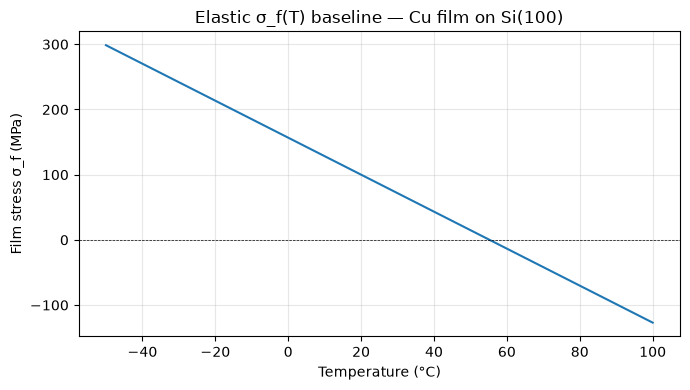

dσ_f/dT = -2.84 MPa/K  (Cu on Si, elastic)


In [18]:
# Copper film on Si(100) as a worked example
# G_f for Cu ≈ E_Cu / (1 - nu_Cu) ≈ 130e9 / (1 - 0.34) ≈ 197 GPa
G_f_Cu     = 197e9    # Pa
alpha_f_Cu = 17.0e-6  # 1/K  (Cu CTE)
sigma_f_ref = 100e6   # Pa  — illustrative starting stress at T_ref

T_array = np.linspace(thermal.T_min, thermal.T_max, 300)
sigma_T = stress_vs_temperature(
    T_array,
    sigma_f_ref = sigma_f_ref,
    T_ref       = thermal.T_ref,
    G_f         = G_f_Cu,
    alpha_f     = alpha_f_Cu,
    alpha_s     = substrate.alpha_s,
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T_array - 273.15, sigma_T / 1e6)
ax.axhline(0, color="k", linewidth=0.5, linestyle="--")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Film stress σ_f (MPa)")
ax.set_title("Elastic σ_f(T) baseline — Cu film on Si(100)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

dsigma_dT = -G_f_Cu * (alpha_f_Cu - substrate.alpha_s)
print(f"dσ_f/dT = {dsigma_dT/1e6:.2f} MPa/K  (Cu on Si, elastic)")